## Лабораторная 4 отчет

### Конфигурация модели и параметры обучения

#### Архитектура и вычислительная среда

В лабораторной работе использовалась акустическая модель **FastSpeech2**, реализованная на основе библиотеки Coqui TTS.

Модель обучалась на русскоязычном речевом корпусе RUSLAN. Входными данными являлись последовательности фонем, выходными данными являлись мел-спектрограммы речевых сигналов.

Основные характеристики модели и среды обучения:

| Параметр | Значение |
|---|---|
| Архитектура | FastSpeech2 |
| Датасет | RUSLAN |
| Число параметров модели | 36 995 297 |
| Фреймворк | PyTorch |
| Вычислительное устройство | NVIDIA GeForce RTX 3060, 12 ГБ VRAM |
| Количество GPU | 1 |
| Количество CPU | 16 логических процессоров |
| Количество потоков PyTorch | 8 |
| Точность вычислений | float32 |
| Mixed precision | Отключена |
| Random seed | 54321 |
| Число шагов на эпоху | 303 |
| Максимальное число эпох | 160 для сравнительных запусков |

При обучении использовались одинаковые архитектура, конфигурация обработки аудио и основные параметры тренера. Между экспериментами изменялись только тип фонетической разметки и заданная скорость обучения.

### Выбор learning rate

Были проведены четыре эксперимента:

| Эксперимент | Фонемы | Learning rate | Количество завершённых эпох |
|---|---|---|---:|
| Baseline | G2P | 1e-3 | 157 |
| GT | Ground Truth | 1e-3 | 160 |
| LR = 1e-4 | G2P | 1e-4 | 160 |
| LR = 5e-3 | G2P | 5e-3 | 160 |

**Обоснование выбора параметров:**

- **LR = 1e-3** использовался как базовое значение, рекомендованное в лабораторной работе. Этот эксперимент служил контрольным для остальных запусков.
- **LR = 1e-4** выбран для исследования влияния меньшей скорости обучения на устойчивость и скорость сходимости. Предполагалось, что уменьшение шага оптимизации может сделать обновление параметров более плавным, но замедлить обучение.
- **LR = 5e-3** выбран для исследования более агрессивной оптимизации. Предполагалось, что увеличение learning rate может ускорить достижение низкой ошибки, но повысить риск нестабильности.
- **GT, LR = 1e-3** использовался для проверки влияния качества фонетической разметки. Сравнение с G2P baseline при одинаковом learning rate позволяет оценить влияние ошибок автоматической фонемизации.

Во всех экспериментах использовался планировщик скорости обучения с постепенным увеличением фактического learning rate на начальной стадии. Поэтому значение learning rate, заданное при запуске, не совпадало с фактическим значением `current_lr` в начале обучения.

### Время обучения

Обучение выполнялось локально на GPU NVIDIA GeForce RTX 3060 с использованием CUDA и PyTorch.

| Эксперимент | Начало обучения | Последняя запись в логе | Продолжительность |
|---|---|---|---|
| Baseline, 1e-3 | 29.10.2026 10:11 | 30.10.2026 10:04 | 23 ч 53 мин |
| GT, 1e-3 | 30.10.2026 10:07 | 31.10.2026 04:37 | 18 ч 30 мин |
| G2P, 1e-4 | 01.11.2026 15:34 | 02.11.2026 15:42 | 24 ч 09 мин |
| G2P, 5e-3 | 31.10.2026 14:54 | 01.11.2026 15:16 | 24 ч 23 мин |

Продолжительность рассчитана по временным отметкам в логах тренера и включает обучение, валидацию, сохранение чекпоинтов и возможные задержки между этапами. Она не является измерением чистого времени работы GPU.

Baseline был остановлен вручную после 157 завершённых эпох. Остальные эксперименты завершили все 160 эпох.

### Предварительные результаты выбора learning rate

По итогам обучения были получены следующие значения валидационной ошибки:

| Эксперимент | Validation loss |
|---|---:|
| G2P, LR = 1e-3 | 2.932 |
| GT, LR = 1e-3 | 2.841 |
| G2P, LR = 1e-4 | 6.470 |
| G2P, LR = 5e-3 | **2.596** |

Наименьшую итоговую валидационную ошибку показал эксперимент с **LR = 5e-3**. Уменьшение learning rate до 1e-4 привело к существенно более медленной сходимости, вследствие чего за одинаковое количество эпох модель не достигла уровня остальных конфигураций.

Использование GT-фонем при LR = 1e-3 обеспечило небольшое улучшение относительно G2P baseline.

Таким образом, по критерию валидационной функции потерь наиболее перспективным оказался эксперимент с LR = 5e-3. Однако окончательный выбор модели должен учитывать не только validation loss, но и MCD, точность предсказания длительностей и субъективную оценку синтезированной речи.

### Кривые loss, отдельно для предсказателя длительностей;

In [2]:
from pathlib import Path
import re

import pandas as pd
import matplotlib.pyplot as plt

LOGS = {
    "G2P, LR=1e-3": "/home/lonaogoda/tts_labs_itmo/labs/lab4_acoustic/runs/baseline/baseline-October-29-2026_10+10AM-20e0198/trainer_0_log.txt",
    "GT, LR=1e-3": "/home/lonaogoda/tts_labs_itmo/labs/lab4_acoustic/runs/gt_lr_1e3/gt_lr_1e3-October-30-2026_10+05AM-20e0198/trainer_0_log.txt",
    "G2P, LR=1e-4": "/home/lonaogoda/tts_labs_itmo/labs/lab4_acoustic/runs/lr_1e4/lr_1e4-November-01-2026_03+32PM-20e0198/trainer_0_log.txt",
    "G2P, LR=5e-3": "/home/lonaogoda/tts_labs_itmo/labs/lab4_acoustic/runs/lr_5e3/lr_5e3-October-31-2026_02+52PM-20e0198/trainer_0_log.txt",
}

OUTPUT_DIR = Path("report_figures")
OUTPUT_DIR.mkdir(exist_ok=True)

# Убираем ANSI-коды цвета из логов Coqui
ANSI_RE = re.compile(r"\x1b\[[0-9;]*m")

EPOCH_RE = re.compile(r">\s*EPOCH:\s*(\d+)/\d+")
METRIC_RE = re.compile(
    r"\|\s*>\s*(avg_[a-z_]+):\s*"
    r"([-+]?\d*\.?\d+(?:[eE][-+]?\d+)?)"
)


def parse_training_log(path):
    text = Path(path).read_text(
        encoding="utf-8",
        errors="replace"
    )
    text = ANSI_RE.sub("", text)

    rows = []
    epoch = None
    in_evaluation = False
    current = {}

    for line in text.splitlines():
        match = EPOCH_RE.search(line)

        if match:
            if in_evaluation and "avg_loss" in current:
                rows.append(current.copy())

            epoch = int(match.group(1))
            current = {}
            in_evaluation = False
            continue

        if "EVAL PERFORMANCE" in line:
            current = {"epoch": epoch + 1}
            in_evaluation = True
            continue

        if in_evaluation:
            metric = METRIC_RE.search(line)

            if metric:
                current[metric.group(1)] = float(
                    metric.group(2)
                )

            if "BEST MODEL" in line:
                if "avg_loss" in current:
                    rows.append(current.copy())

                current = {}
                in_evaluation = False

    if in_evaluation and "avg_loss" in current:
        rows.append(current)

    df = pd.DataFrame(rows)

    if df.empty:
        raise ValueError(f"Нет метрик в файле: {path}")

    return (
        df.drop_duplicates(subset="epoch")
        .sort_values("epoch")
        .reset_index(drop=True)
    )


histories = {}

for model_name, log_file in LOGS.items():
    if not Path(log_file).exists():
        raise FileNotFoundError(
            f"Файл {log_file} не найден. "
            "Проверь расположение логов."
        )

    histories[model_name] = parse_training_log(log_file)

    print(
        f"{model_name}: "
        f"{len(histories[model_name])} эпох"
    )

G2P, LR=1e-3: 157 эпох
GT, LR=1e-3: 160 эпох
G2P, LR=1e-4: 160 эпох
G2P, LR=5e-3: 160 эпох


In [3]:
plt.rcParams.update({
    "figure.figsize": (11, 5),
    "font.size": 11,
    "axes.grid": True,
    "grid.alpha": 0.25,
})

COLORS = {
    "G2P, LR=1e-3": "tab:blue",
    "GT, LR=1e-3": "tab:green",
    "G2P, LR=1e-4": "tab:orange",
    "G2P, LR=5e-3": "tab:red",
}


def plot_loss(metric, title, ylabel, filename):
    fig, ax = plt.subplots()

    for name, df in histories.items():
        ax.plot(
            df["epoch"],
            df[metric],
            label=name,
            color=COLORS[name],
            linewidth=2,
        )

    ax.set_title(title)
    ax.set_xlabel("Эпоха")
    ax.set_ylabel(ylabel)
    ax.legend()
    ax.set_xlim(left=1)

    fig.tight_layout()

    fig.savefig(
        OUTPUT_DIR / filename,
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

Графики общего loss и спектрограммы

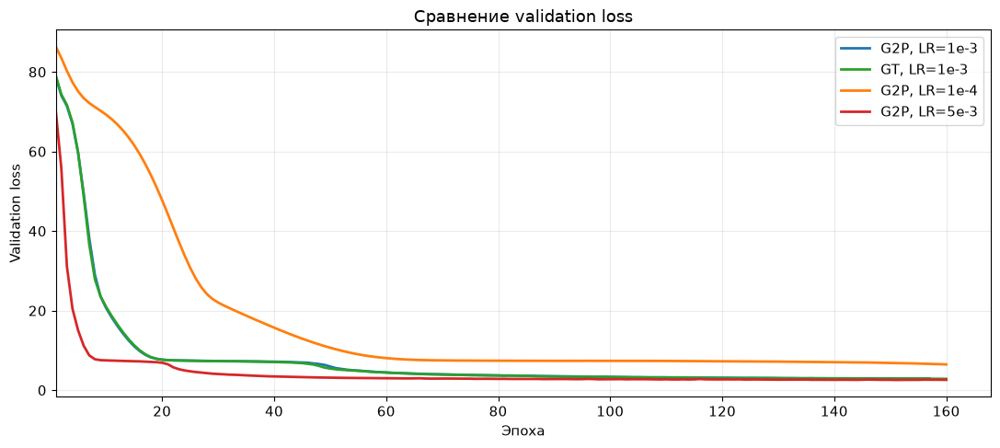

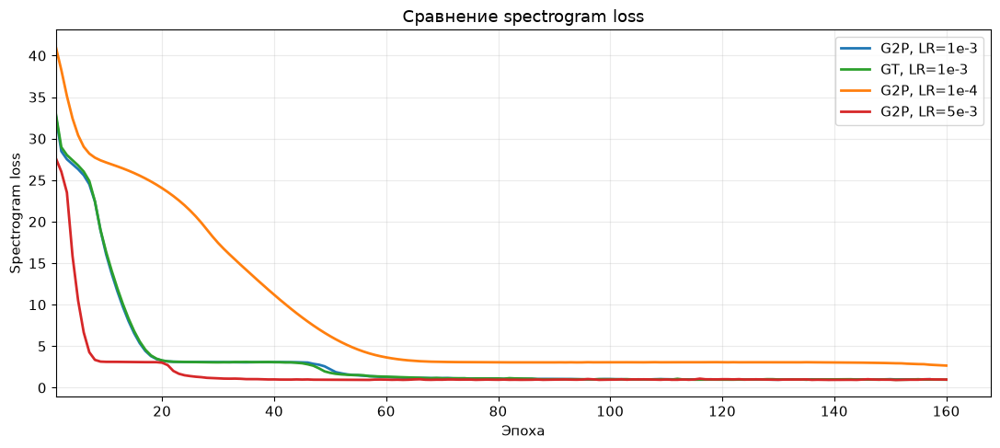

In [4]:
plot_loss(
    metric="avg_loss",
    title="Сравнение validation loss",
    ylabel="Validation loss",
    filename="validation_loss.png"
)

plot_loss(
    metric="avg_loss_spec",
    title="Сравнение spectrogram loss",
    ylabel="Spectrogram loss",
    filename="spectrogram_loss.png"
)

графики предсказателя длительностей

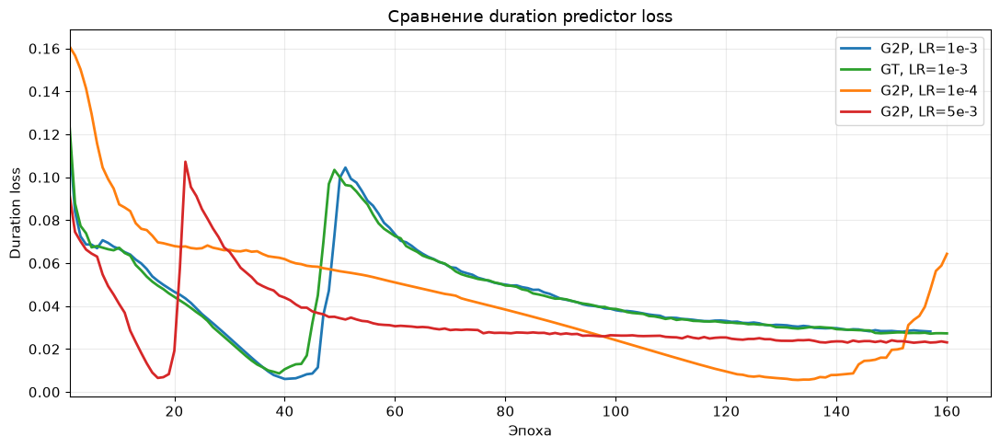

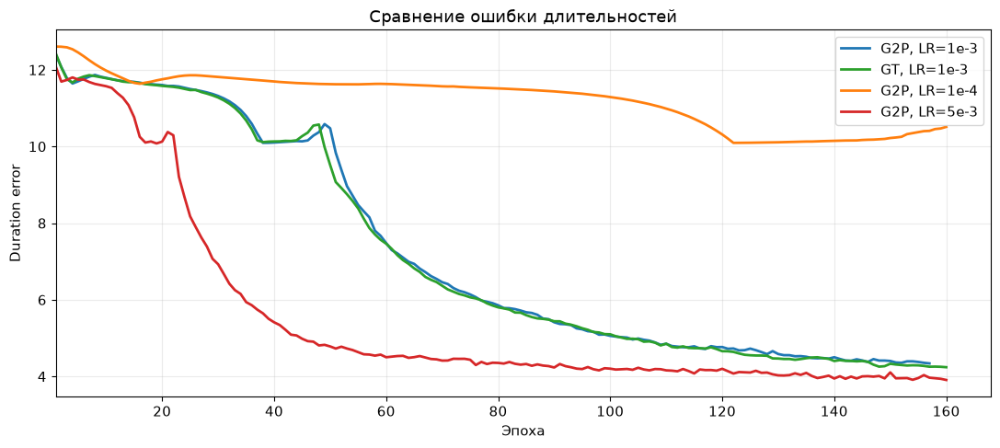

In [5]:
plot_loss(
    metric="avg_loss_dur",
    title="Сравнение duration predictor loss",
    ylabel="Duration loss",
    filename="duration_loss.png"
)

plot_loss(
    metric="avg_duration_error",
    title="Сравнение ошибки длительностей",
    ylabel="Duration error",
    filename="duration_error.png"
)

Графики loss почле 40 эпохи

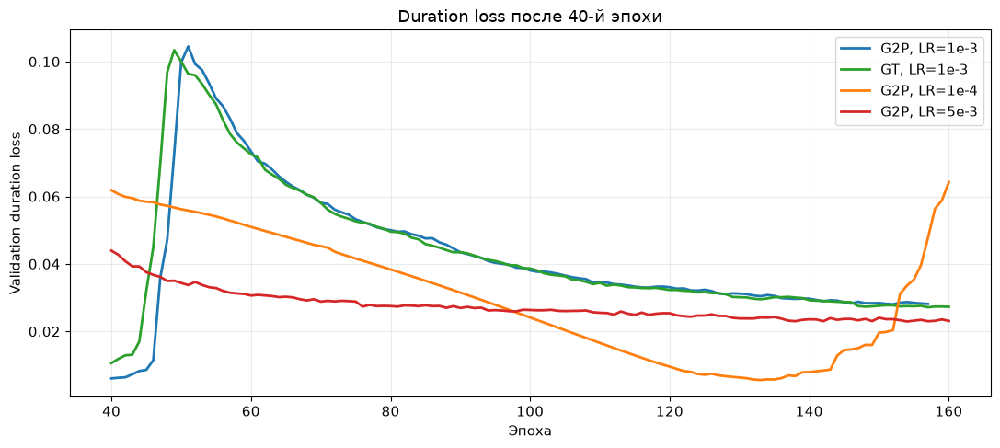

In [6]:
fig, ax = plt.subplots(figsize=(11, 5))

for name, df in histories.items():
    subset = df[df["epoch"] >= 40]

    ax.plot(
        subset["epoch"],
        subset["avg_loss_dur"],
        label=name,
        color=COLORS[name],
        linewidth=2
    )

ax.set_title("Duration loss после 40-й эпохи")
ax.set_xlabel("Эпоха")
ax.set_ylabel("Validation duration loss")
ax.legend()

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "duration_loss_after_40.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

Сводная таблица метрик

In [7]:
summary = []

for name, df in histories.items():
    last = df.iloc[-1]

    summary.append({
        "Модель": name,
        "Эпох": len(df),
        "Validation loss": last["avg_loss"],
        "Spectrogram loss": last["avg_loss_spec"],
        "Duration loss": last["avg_loss_dur"],
        "Duration error": last["avg_duration_error"],
    })

summary_df = pd.DataFrame(summary)

display(summary_df.round(4))

,Модель,Эпох,Validation loss,Spectrogram loss,Duration loss,Duration error
0,"G2P, LR=1e-3",157,2.9320,1.0223,0.0281,4.3398
1,"GT, LR=1e-3",160,2.8414,0.9664,0.0273,4.2410
2,"G2P, LR=1e-4",160,6.4698,2.6628,0.0643,10.5112
3,"G2P, LR=5e-3",160,2.5960,0.9792,0.0231,3.9082


#### Анализ кривых обучения FastSpeech2

Для анализа процесса обучения были построены графики изменения общей валидационной ошибки (`validation loss`), ошибки предсказания мел-спектрограмм (`spectrogram loss`), ошибки предсказателя длительностей (`duration loss`) и ошибки длительностей (`duration error`).

Сравнивались четыре конфигурации модели FastSpeech2:

- G2P-фонемы, learning rate = \(10^{-3}\) (baseline);
- GT-фонемы, learning rate = \(10^{-3}\);
- G2P-фонемы, learning rate = \(10^{-4}\);
- G2P-фонемы, learning rate = \(5 \cdot 10^{-3}\).

##### 1. Общая валидационная ошибка (Validation loss)

Все четыре модели демонстрируют снижение общей валидационной ошибки в процессе обучения, однако скорость сходимости заметно различается.

Наиболее быстрая сходимость наблюдается у модели с **LR = \(5 \cdot 10^{-3}\)**. Уже в первые 20–30 эпох ошибка значительно уменьшается, после чего снижение становится более плавным. Итоговое значение `validation loss` составляет **2.5960**, что является лучшим результатом среди рассмотренных конфигураций.

Модели G2P и GT с LR = \(10^{-3}\) демонстрируют близкую динамику обучения. После приблизительно 50–60 эпох их ошибки постепенно стабилизируются. Итоговые значения составляют **2.9320** для G2P и **2.8414** для GT. Таким образом, использование эталонных фонем обеспечивает небольшое улучшение общей ошибки при одинаковой скорости обучения.

Наиболее медленная сходимость наблюдается при **LR = \(10^{-4}\)**. Даже после 160 эпох итоговая ошибка остаётся существенно выше остальных и составляет **6.4698**.

##### 2. Ошибка предсказания мел-спектрограмм (Spectrogram loss)

Графики `spectrogram loss` демонстрируют аналогичную закономерность.

При LR = \(5 \cdot 10^{-3}\) спектральная ошибка быстро уменьшается и достигает значения **0.9792** к концу обучения. Модель с GT-фонемами показывает итоговое значение **0.9664**, что является минимальным среди четырёх экспериментов.

Для базовой G2P-модели с LR = \(10^{-3}\) ошибка составляет **1.0223**. Различия между этими тремя моделями сравнительно невелики, что указывает на достижение ими близкого уровня качества предсказания мел-спектрограмм.

При LR = \(10^{-4}\) итоговый `spectrogram loss` равен **2.6628**, то есть модель не достигла сопоставимого качества восстановления акустических признаков за заданное количество эпох.

##### 3. Ошибка предсказателя длительностей (Duration loss)

Отдельно анализировалась ошибка предсказателя длительностей, определяющего количество акустических кадров, соответствующих входным фонемам.

Наиболее низкое итоговое значение `duration loss` получено для модели **G2P с LR = \(5 \cdot 10^{-3}\)**: **0.0231**.

Для остальных конфигураций результаты следующие:

| Конфигурация | Duration loss |
|---|---:|
| G2P, LR = 1e-3 | 0.0281 |
| GT, LR = 1e-3 | 0.0273 |
| G2P, LR = 1e-4 | 0.0643 |
| G2P, LR = 5e-3 | **0.0231** |

Интересной особенностью является поведение моделей с LR = \(10^{-3}\). Приблизительно на 46–50-й эпохах наблюдается резкое увеличение `duration loss`, после которого ошибка снова постепенно уменьшается. Похожая динамика присутствует одновременно в G2P- и GT-экспериментах.

Это может быть связано с перестройкой выравнивания фонем и акустических кадров в ходе обучения. Поскольку подобное поведение наблюдается у обеих конфигураций с одинаковым learning rate, оно, вероятно, обусловлено динамикой совместного обучения акустической модели, выравнивателя и предсказателя длительностей, а не исключительно качеством фонетической разметки.

Для модели с LR = \(5 \cdot 10^{-3}\) временный рост `duration loss` происходит раньше, приблизительно на 23-й эпохе. После этого ошибка снижается и постепенно стабилизируется.

При LR = \(10^{-4}\) ситуация отличается: после продолжительного уменьшения `duration loss` до минимума приблизительно на 130-й эпохе ошибка начинает расти, особенно заметно на последних 10–15 эпохах. Это указывает на ухудшение валидационной ошибки предсказателя длительностей к концу обучения. Возможное объяснение заключается в недостаточной согласованности обучения акустической модели, выравнивателя и предсказателя длительностей при малом learning rate.

##### 4. Ошибка длительностей (Duration error)

Дополнительно рассматривалась метрика `duration error`, позволяющая оценить расхождение между предсказанными и эталонными длительностями.

Итоговые значения:

| Конфигурация | Duration error |
|---|---:|
| G2P, LR = 1e-3 | 4.3398 |
| GT, LR = 1e-3 | 4.2410 |
| G2P, LR = 1e-4 | 10.5112 |
| G2P, LR = 5e-3 | **3.9082** |

Лучший результат снова показывает модель с LR = \(5 \cdot 10^{-3}\). Она быстрее остальных снижает ошибку длительностей и достигает наиболее низкого итогового значения.

Модели с LR = \(10^{-3}\) постепенно уменьшают ошибку и к концу обучения достигают близких результатов. Использование GT-фонем даёт небольшое преимущество относительно G2P.

Модель с LR = \(10^{-4}\) практически на протяжении всего обучения сохраняет высокую ошибку длительностей. К концу обучения она составляет **10.5112**, что значительно хуже остальных экспериментов.

##### 5. Выводы по кривым обучения

По результатам анализа можно сделать следующие выводы:

1. **Наиболее эффективной по совокупности валидационных метрик оказалась модель с G2P-фонемами и LR = \(5 \cdot 10^{-3}\)**. Она обеспечивает наиболее быструю сходимость, минимальные итоговые `validation loss`, `duration loss` и `duration error`.
2. **GT-фонемы немного улучшают результаты при LR = \(10^{-3}\)**. При этом различие между GT и G2P значительно меньше, чем влияние изменения learning rate.
3. **LR = \(10^{-4}\) оказался недостаточным для достижения сопоставимого качества за 160 эпох**. Модель сходится медленно и сохраняет высокую ошибку длительностей. Дополнительно наблюдается увеличение `duration loss` в конце обучения.
4. Минимальный итоговый `spectrogram loss` получен для GT-модели с LR = \(10^{-3}\), хотя различие с моделью LR = \(5 \cdot 10^{-3}\) невелико.
5. Наблюдаемые скачки `duration loss` могут быть связаны с процессом формирования и уточнения выравнивания фонем и акустических кадров. Для подтверждения гипотезы необходимо дополнительно исследовать метрики и визуализации выравнивания.

Таким образом, **для дальнейшей акустической оценки основным кандидатом выбрана модель G2P с LR = \(5 \cdot 10^{-3}\)**. Окончательное заключение о качестве синтеза будет сделано после сравнения MCD, длительностей и прослушивания аудиозаписей `natural`, `copysynth` и `model`.

### Замеры MCD и отношения числа кадров

Загрузка результатов четырёх моделей

In [8]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

RUNS = {
    "G2P, LR=1e-3": Path(
        "/home/lonaogoda/tts_labs_itmo/labs/lab4_acoustic/runs/baseline/baseline-October-29-2026_10+10AM-20e0198/eval/"
    ),
    "GT, LR=1e-3": Path(
        "/home/lonaogoda/tts_labs_itmo/labs/lab4_acoustic/runs/gt_lr_1e3/gt_lr_1e3-October-30-2026_10+05AM-20e0198/eval/"
    ),
    "G2P, LR=1e-4": Path(
        "/home/lonaogoda/tts_labs_itmo/labs/lab4_acoustic/runs/lr_1e4/lr_1e4-November-01-2026_03+32PM-20e0198/eval/"
    ),
    "G2P, LR=5e-3": Path(
        "/home/lonaogoda/tts_labs_itmo/labs/lab4_acoustic/runs/lr_5e3/lr_5e3-October-31-2026_02+52PM-20e0198/eval/"
    ),
}

eval_data = {}

for name, eval_dir in RUNS.items():
    csv_path = eval_dir / "mcd.csv"

    if not csv_path.exists():
        print(f"Нет результатов оценки: {csv_path}")
        continue

    df = pd.read_csv(csv_path, sep="|")
    df.columns = df.columns.str.strip()

    required = {
        "id",
        "frames_natural",
        "frames_model",
        "mcd_model",
        "mcd_constant",
    }

    missing = required - set(df.columns)

    if missing:
        raise ValueError(
            f"{csv_path}: отсутствуют столбцы {missing}"
        )

    eval_data[name] = df

    print(f"{name}: {len(df)} предложений")

G2P, LR=1e-3: 120 предложений
GT, LR=1e-3: 120 предложений
G2P, LR=1e-4: 120 предложений
G2P, LR=5e-3: 120 предложений


Сводная таблица

In [9]:
results = []

for name, df in eval_data.items():
    frame_ratio = (
        df["frames_model"].sum()
        / df["frames_natural"].sum()
    )

    results.append({
        "Модель": name,
        "MCD модели, dB": df["mcd_model"].mean(),
        "MCD constant, dB": df["mcd_constant"].mean(),
        "Frame ratio": frame_ratio,
        "Предложений": len(df),
    })

metrics_df = pd.DataFrame(results)

display(metrics_df.round(3))

,Модель,"MCD модели, dB","MCD constant, dB",Frame ratio,Предложений
0,"G2P, LR=1e-3",28.383,66.696,0.796,120
1,"GT, LR=1e-3",28.161,66.696,0.837,120
2,"G2P, LR=1e-4",51.732,66.696,0.470,120
3,"G2P, LR=5e-3",27.514,66.696,0.851,120


График сравнения MCD

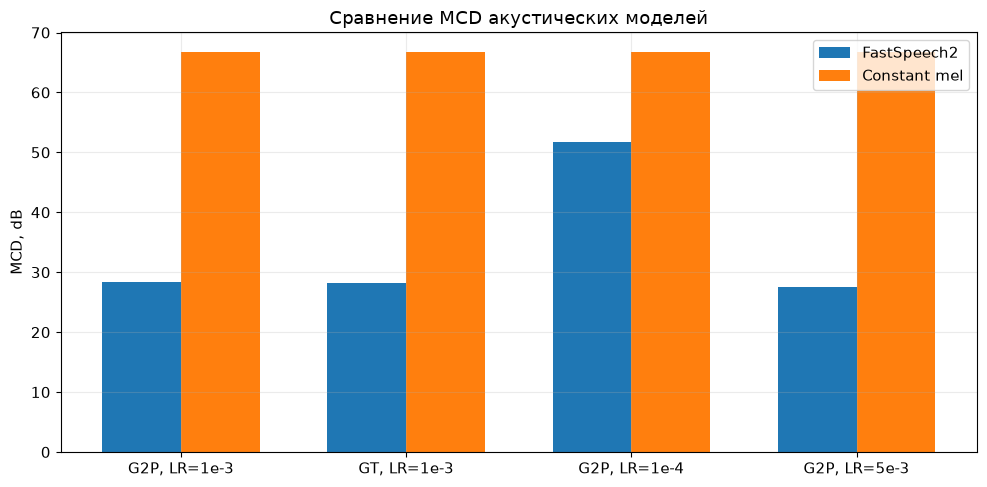

In [10]:
fig, ax = plt.subplots(figsize=(10, 5))

x = np.arange(len(metrics_df))
width = 0.35

ax.bar(
    x - width / 2,
    metrics_df["MCD модели, dB"],
    width,
    label="FastSpeech2"
)

ax.bar(
    x + width / 2,
    metrics_df["MCD constant, dB"],
    width,
    label="Constant mel"
)

ax.set_xticks(x)
ax.set_xticklabels(metrics_df["Модель"])
ax.set_ylabel("MCD, dB")
ax.set_title("Сравнение MCD акустических моделей")
ax.legend()
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

График отношения числа кадров

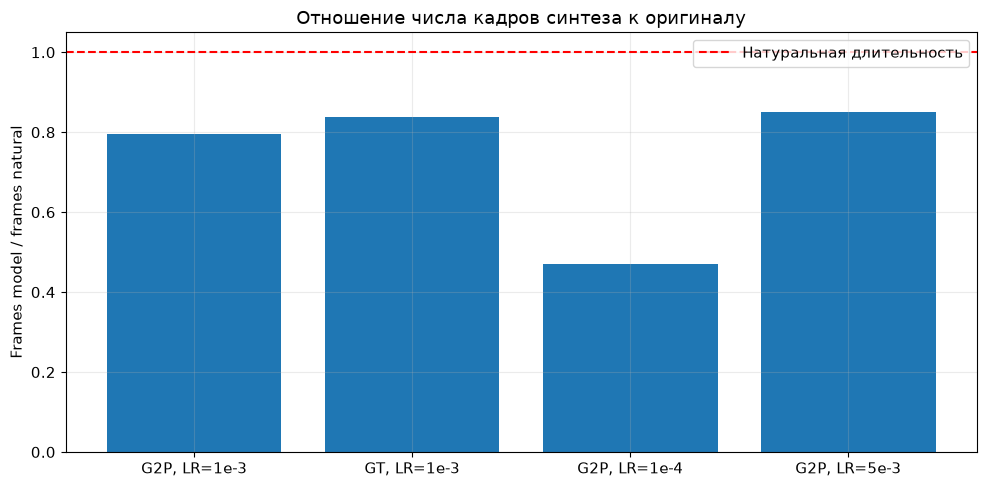

In [11]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    metrics_df["Модель"],
    metrics_df["Frame ratio"]
)

ax.axhline(
    y=1.0,
    color="red",
    linestyle="--",
    label="Натуральная длительность"
)

ax.set_title("Отношение числа кадров синтеза к оригиналу")
ax.set_ylabel("Frames model / frames natural")
ax.legend()
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

Диапазоны мел-спектрограмм

,Модель,Min,Max,Ширина
0,Natural,-11.48,0.57,12.05
1,"G2P, LR=1e-3",-10.84,-0.15,10.69
2,"GT, LR=1e-3",-10.94,-0.01,10.93
3,"G2P, LR=1e-4",-10.32,-1.42,8.90
4,"G2P, LR=5e-3",-11.01,0.06,11.07


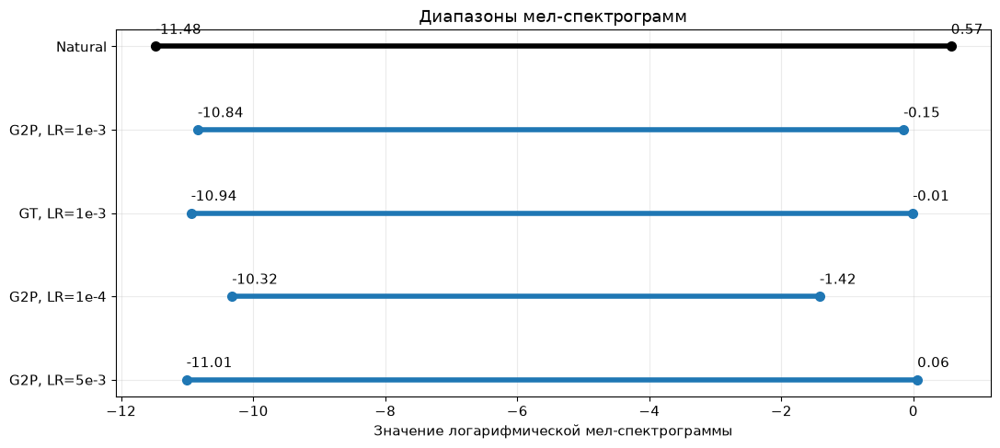

In [12]:
import pandas as pd
import matplotlib.pyplot as plt

mel_ranges = pd.DataFrame({
    "Модель": [
        "Natural",
        "G2P, LR=1e-3",
        "GT, LR=1e-3",
        "G2P, LR=1e-4",
        "G2P, LR=5e-3",
    ],
    "Min": [-11.48, -10.84, -10.94, -10.32, -11.01],
    "Max": [0.57, -0.15, -0.01, -1.42, 0.06],
})

mel_ranges["Ширина"] = mel_ranges["Max"] - mel_ranges["Min"]

display(mel_ranges.round(2))

fig, ax = plt.subplots(figsize=(11, 5))

for i, row in mel_ranges.iterrows():
    color = "black" if row["Модель"] == "Natural" else "tab:blue"

    ax.plot(
        [row["Min"], row["Max"]],
        [i, i],
        marker="o",
        linewidth=4,
        markersize=7,
        color=color
    )

    ax.text(row["Min"], i - 0.15, f'{row["Min"]:.2f}')
    ax.text(row["Max"], i - 0.15, f'{row["Max"]:.2f}')

ax.set_yticks(range(len(mel_ranges)))
ax.set_yticklabels(mel_ranges["Модель"])
ax.invert_yaxis()

ax.set_xlabel("Значение логарифмической мел-спектрограммы")
ax.set_title("Диапазоны мел-спектрограмм")
ax.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.savefig("mel_ranges.png", dpi=200, bbox_inches="tight")
plt.show()

#### Анализ диапазонов мел-спектрограмм

Для оценки распределения значений акустических признаков были сопоставлены минимальные и максимальные значения логарифмических мел-спектрограмм натуральной речи и предсказаний четырёх моделей FastSpeech2.

Диапазон натуральных мел-спектрограмм составил **[-11.48; 0.57]**, его ширина равна **12.05**.

Все обученные модели воспроизводят более узкий диапазон значений, чем натуральная речь. Наиболее близкий к эталонному диапазон получен для конфигурации **G2P с LR = 5 · 10⁻³**: **[-11.01; 0.06]**, ширина **11.07**.

Модель с GT-фонемами и LR = 10⁻³ показала диапазон **[-10.94; -0.01]**, а базовая G2P-модель с тем же learning rate — **[-10.84; -0.15]**. Таким образом, использование эталонных фонем позволило немного улучшить воспроизведение крайних значений мел-спектрограммы.

Наибольшее отклонение наблюдается у модели G2P с LR = 10⁻⁴. Её диапазон составил **[-10.32; -1.42]**, ширина **8.90**. Это указывает на наиболее выраженное сужение диапазона предсказанных акустических признаков.

Полученные результаты согласуются со сравнением MCD: модель с LR = 5 · 10⁻³ демонстрирует наименьшее спектральное расхождение, а модель с LR = 10⁻⁴ — наибольшее.

Таким образом, по диапазону значений мел-спектрограмм наиболее успешной оказалась конфигурация **G2P с LR = 5 · 10⁻³**. При этом совпадение минимальных и максимальных значений не гарантирует полного совпадения спектральной структуры, поэтому данный показатель рассматривается совместно с MCD.

In [13]:
from IPython.display import Audio, display, Markdown

sample_ids = [
    "009970_RUSLAN",
    "005315_RUSLAN",
    "001355_RUSLAN",
    "002625_RUSLAN",
    "015300_RUSLAN",
    "005720_RUSLAN",
]

def listen_sample(sample_id):
    display(Markdown(f"## Предложение `{sample_id}`"))

    # Эталон и восстановленная эталонная речь
    baseline_dir = RUNS["G2P, LR=1e-3"]

    for folder in ["natural", "copysynth"]:
        path = baseline_dir / folder / f"{sample_id}.wav"
        display(Markdown(f"**{folder}**"))
        display(Audio(filename=str(path)))

    # Синтез для каждой обученной модели
    for model_name, eval_dir in RUNS.items():
        path = eval_dir / "model" / f"{sample_id}.wav"

        display(Markdown(f"**{model_name}**"))
        display(Audio(filename=str(path)))


for sample_id in sample_ids:
    listen_sample(sample_id)

## Предложение `009970_RUSLAN`

**natural**

**copysynth**

**G2P, LR=1e-3**

**GT, LR=1e-3**

**G2P, LR=1e-4**

... (32 outputs left out)

**G2P, LR=1e-3**

**GT, LR=1e-3**

**G2P, LR=1e-4**

**G2P, LR=5e-3**

### Субъективная акустическая оценка синтезированной речи

#### Методика оценки

Для субъективного анализа были выбраны 6 предложений из тестового набора RUSLAN:

- `009970_RUSLAN` — пример с низким MCD;
- `005315_RUSLAN` — оценка разборчивости и произношения окончаний;
- `001355_RUSLAN` — пример с существенным сокращением длительности;
- `002625_RUSLAN` — длинное предложение для оценки пауз и ритма;
- `015300_RUSLAN` — оценка устойчивости произношения и интонации;
- `005720_RUSLAN` — короткая фраза для оценки разборчивости.

Для каждого предложения сравнивались исходная запись диктора (`natural`), восстановление эталонной мел-спектрограммы с помощью Griffin-Lim (`copysynth`) и синтезированные записи (`model`) четырёх конфигураций FastSpeech2.

Анализ проводился на слух по следующим критериям:

1. **Фонетическое качество:** разборчивость речи, правильность произношения гласных и согласных, сохранение окончаний, отсутствие пропусков и слияния звуков.
2. **Мелодическое качество:** естественность интонации, сохранение ритма, акцентов, пауз и темпа речи.
3. **Акустические артефакты:** глухое или металлическое звучание, роботизированные эффекты, шум и бульканье.

#### Сравнение natural и copysynth

Во всех шести примерах восстановленная через Griffin-Lim речь оставалась разборчивой и сохраняла фонетическую структуру исходного предложения.

При этом по сравнению с натуральной речью наблюдалось более глухое, низкое и приглушённое звучание. В некоторых примерах присутствовали слабые дополнительные артефакты, напоминающие бульканье.

Наиболее заметные отличия касались тембра и общего качества аудиосигнала, тогда как произношение слов оставалось понятным.

Таким образом, используемый метод восстановления аудио вносит слышимые искажения, но сам по себе не приводит к существенной потере разборчивости речи. Более выраженные ошибки в записях `model` связаны с результатом акустического предсказания и последующего восстановления звука.

#### Оценка фонетического качества моделей

**G2P, LR = 1e-3 (baseline).**

Модель обеспечивает преимущественно разборчивую речь, однако в отдельных предложениях наблюдаются пропуски гласных и согласных, нечёткое произношение окончаний и слияние соседних звуков.

В предложении `005315_RUSLAN` отмечено искажение произношения слова «разговаривать», а в `001355_RUSLAN` модель значительно сократила оба слова и не воспроизвела их окончания полностью.

В длинном предложении `002625_RUSLAN` некоторые слова сливались из-за сокращения пауз и ускоренного произношения.

В коротком примере `005720_RUSLAN` речь оставалась разборчивой, хотя в начале слова наблюдалось слияние звуков.

**GT, LR = 1e-3.**

Использование эталонной фонетической разметки обеспечило более устойчивое произношение в нескольких тестовых примерах.

В предложении `005315_RUSLAN` GT-модель лучше воспроизвела окончания по сравнению с G2P baseline. В `005720_RUSLAN` речь также оказалась более чёткой и разборчивой.

В длинном предложении `002625_RUSLAN` модель лучше разделяла слова и сохраняла паузы, хотя отдельные фонетические ошибки и сокращение длительности сохранялись.

Таким образом, GT-модель в ряде примеров показала преимущество по точности произношения, однако полностью устранить пропуски звуков и искажения окончаний не удалось.

**G2P, LR = 1e-4.**

Данная конфигурация показала наиболее низкое субъективное качество.

Во всех шести примерах вместо связной речи преимущественно воспроизводился шум с колебаниями и отдельными речеподобными звуками. Слова практически невозможно было разобрать.

Особенно заметно это в предложении `002625_RUSLAN`, где длительность сократилась примерно с 14 до 4 секунд без сохранения разборчивой речевой структуры.

В коротком предложении `005720_RUSLAN` можно было различить лишь слабую попытку воспроизведения слова «можно».

Следовательно, при LR = 1e-4 модель за 160 эпох не достигла приемлемого фонетического качества синтеза.

**G2P, LR = 5e-3.**

Модель показала неоднородные результаты в зависимости от предложения.

В `005315_RUSLAN` она достаточно чётко воспроизвела окончания и по качеству произношения была сопоставима с GT-моделью.

В `015300_RUSLAN` после отдельных ошибок в начале фразы произношение стало более чётким, чем у остальных G2P-конфигураций. Этот пример был субъективно оценён как один из наиболее удачных.

Однако в `009970_RUSLAN` и `001355_RUSLAN` отмечались пропуски звуков, нечёткие окончания и слияние согласных. В этих случаях модель уступала G2P baseline и GT по отдельным фонетическим характеристикам.

Таким образом, несмотря на лучшие объективные метрики, конфигурация LR = 5e-3 не демонстрирует однозначного фонетического преимущества во всех прослушанных примерах.

#### Оценка мелодического качества

У всех трёх конфигураций, способных воспроизводить разборчивую речь, наблюдались отличия от натуральной интонации.

**G2P, LR = 1e-3** часто воспроизводила речь с более ровной, монотонной интонацией. В некоторых случаях отмечались роботизированные призвуки и ускорение отдельных слов. Паузы между словами не всегда сохранялись, что делало речь менее естественной.

**GT, LR = 1e-3** в нескольких примерах лучше сохраняла исходный ритм. Особенно это заметно в `001355_RUSLAN` и `002625_RUSLAN`. Однако интонационные акценты всё равно отличались от оригинала, а общая длительность нередко сокращалась.

**G2P, LR = 1e-4** не позволила провести содержательную оценку мелодики, поскольку большинство записей представляли собой неразборчивый шум, а не связную речь.

**G2P, LR = 5e-3** в некоторых примерах лучше воспроизводила продолжительность и общий характер интонации. В `015300_RUSLAN` звучание оказалось ближе к натуральному по мелодике. Однако в отдельных фразах сохранялись ускорения, пропуски звуков и нарушения ритма.

#### Анализ длительности речи

При прослушивании было обнаружено систематическое сокращение длительности большинства синтезированных предложений.

Показательные примеры:

| Предложение | Natural | G2P 1e-3 | GT 1e-3 | G2P 1e-4 | G2P 5e-3 |
|---|---:|---:|---:|---:|---:|
| `009970_RUSLAN` | ~7 с | ~6 с | ~6 с | ~4 с | ~7 с |
| `001355_RUSLAN` | ~2 с | ~1 с | Ближе к оригиналу | Неразборчиво | Ближе к оригиналу |
| `002625_RUSLAN` | ~14 с | ~9 с | ~10 с | ~4 с | ~10 с |
| `015300_RUSLAN` | ~11 с | ~8 с | ~8 с | ~4 с | ~9 с |

*Длительности указаны приблизительно по результатам прослушивания.*

Наиболее значительные нарушения темпа и длительности наблюдались при LR = 1e-4.

Для остальных конфигураций сокращение длительности часто сопровождалось пропусками фонем, слиянием звуков и уменьшением пауз. Это согласуется с результатами количественной оценки отношения числа кадров.

#### Итоговое сравнение

| Конфигурация | Фонетическое качество | Мелодическое качество |
|---|---|---|
| Natural | Эталонное произношение | Естественная интонация и ритм |
| Copysynth | Разборчивое, близкое к оригиналу | Сохраняет исходный ритм, но звучит более глухо |
| G2P, LR = 1e-3 | В основном разборчиво, встречаются пропуски и слияния звуков | Более ровная интонация, ускорения и сокращение пауз |
| GT, LR = 1e-3 | Часто лучше baseline воспроизводит окончания и отдельные фонемы | В ряде примеров лучше сохраняет ритм, но отличается от оригинала |
| G2P, LR = 1e-4 | Преимущественно неразборчивый шум | Содержательная оценка невозможна |
| G2P, LR = 5e-3 | В целом разборчиво, но качество зависит от фразы | В отдельных примерах ближе к оригиналу, сохраняются нарушения ритма |

#### Вывод

Субъективная оценка показала, что качество синтезированной речи зависит не только от значения валидационной ошибки и MCD, но и от точности воспроизведения фонем, окончаний, пауз и интонации.

Модель с LR = 1e-4 оказалась неудовлетворительной как по объективным, так и по субъективным показателям: вместо разборчивой речи преимущественно воспроизводился шум.

Модели G2P и GT с LR = 1e-3 продемонстрировали приемлемую разборчивость, причём GT в нескольких случаях лучше воспроизводила окончания и сохраняла паузы.

Модель G2P с LR = 5e-3 достигла наименьшего MCD и наиболее близкой к эталону суммарной длительности, однако при прослушивании не во всех примерах превосходила GT и базовую G2P-модель по фонетическому качеству.

**Таким образом, наиболее успешной по объективным метрикам является модель G2P с LR = 5e-3, тогда как GT с LR = 1e-3 в ряде предложений обеспечивает более точное и разборчивое произношение.**

Основными недостатками полученных моделей остаются сокращение длительности речи, пропуски фонем и окончаний, недостаточно естественная интонация и акустические артефакты.